In [1]:
import pandas as pd

df = pd.read_csv('long_091826.csv')

top_peptides = pd.read_csv('pep_hits_wo_taxa_to_remove_091826.csv')

peps_metadata = pd.read_csv("lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv")
peps_metadata = peps_metadata.set_index('seq_id')

In [2]:
#from long to wide
plot_df = df.pivot(index='peptide', columns='individual', values='z_score')

#subset peps metadata to pep hits
pep_hits_meta = peps_metadata.loc[plot_df.index]

In [3]:
prefix_sl = ("C-", "S-")
cols = sorted([c for c in plot_df.columns if c.startswith(prefix_sl)])
cols_other = [c for c in plot_df.columns if c not in cols]
new_order = cols + cols_other
plot_df = plot_df[new_order]


n_c = sum(c.startswith("C-") for c in plot_df.columns)
n_cs = len(cols)  # all C- and S- columns

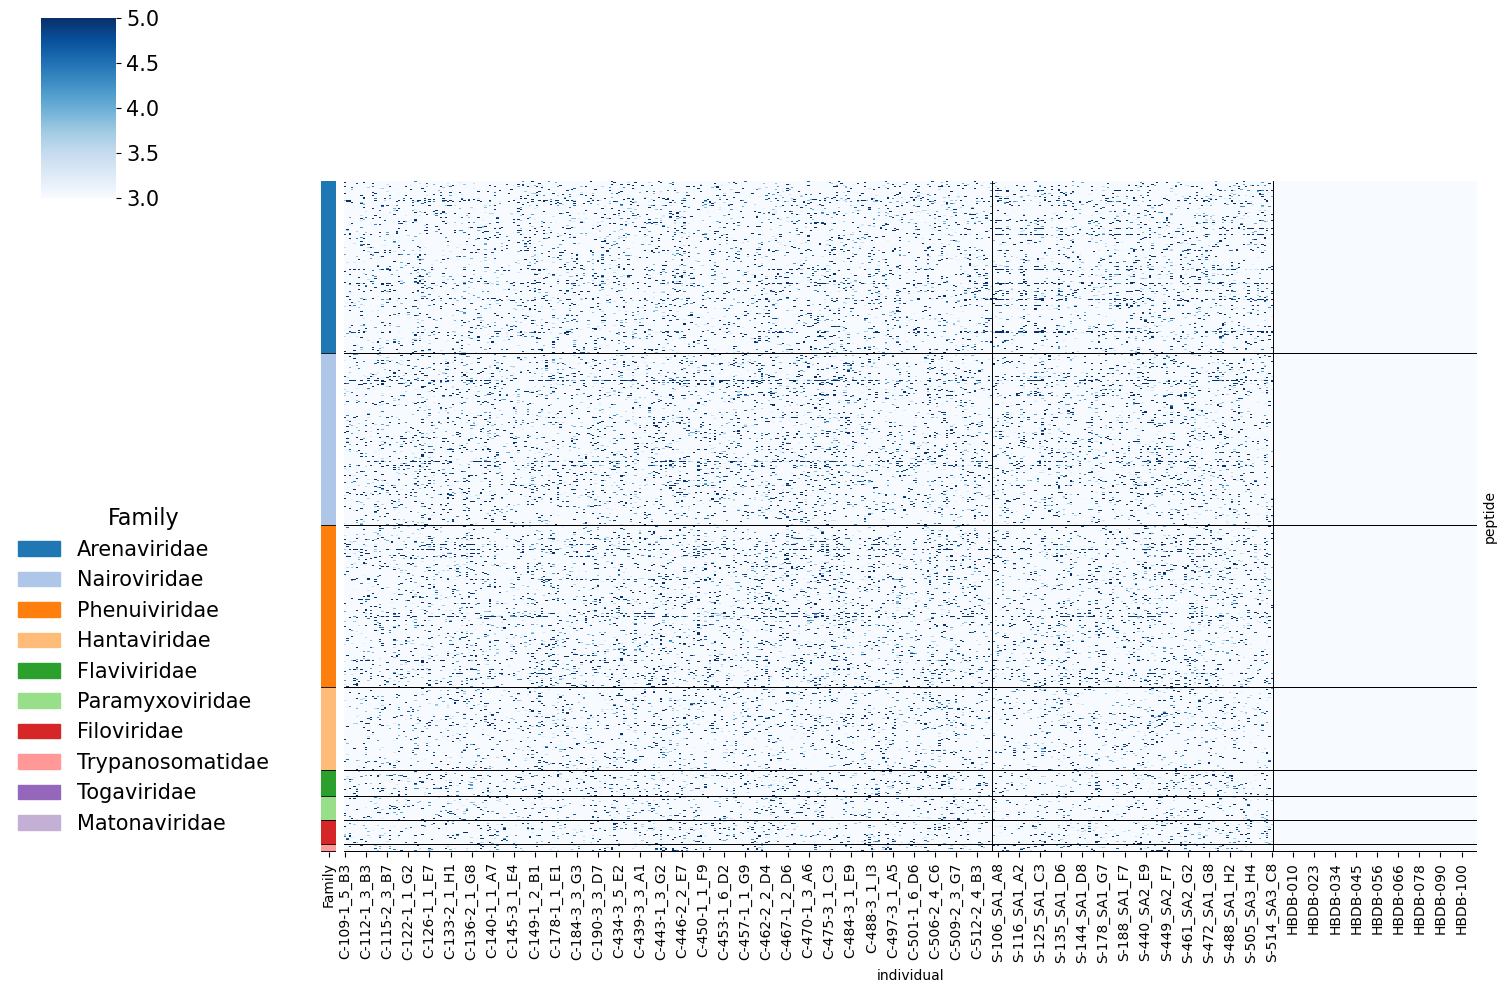

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

#sort by genus
pep_hits_meta = pep_hits_meta.sort_values(by=['family', 'species'])

# sort families by size (largest first), then by species within each family
pep_hits_meta['family_n'] = pep_hits_meta.groupby('family')['family'].transform('size')
pep_hits_meta = pep_hits_meta.sort_values(
    by=['family_n', 'family', 'species'],
    ascending=[False, True, True],
).drop(columns='family_n')

plot_df = plot_df.reindex(pep_hits_meta.index)

genera = pep_hits_meta['family'].unique()   # now ordered largest -> smallest

plot_df = plot_df.reindex(pep_hits_meta.index)

#one color per genus
genera = pep_hits_meta['family'].unique() #order follows the sort

palette = sns.color_palette('tab20', n_colors=len(genera))
genus_lut = dict(zip(genera, palette)) #zip pairs up two lists item by item, dict turns them into key -> value

#.map(genus_lut) swaps each genus name in the column for its color in the dictionary. 
# result is Series of color with one entry per peptide, keeps same index as pep_hits_meta
#clustermap uses that index to match each color to its row in plot_df
#.Genus changes the Series' name from the column. purely cosmetic, as clustermap will write this name next to color strip
row_colors = pep_hits_meta['family'].map(genus_lut).rename('Family')

g = sns.clustermap(
    plot_df, 
    row_cluster=False, 
    col_cluster=False, 
    row_colors=row_colors, 
    colors_ratio=0.01,
    cmap='Blues', 
    yticklabels=False, 
    rasterized=True,
    figsize=(15, 10),
    vmin=3, vmax=5
)

# group dividers
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

handles = [mpatches.Patch(color=genus_lut[gn], label=gn) for gn in genera]
g.ax_heatmap.legend(handles=handles, title='Family', loc='lower right', frameon=False, bbox_to_anchor=(-0.05, 0),
            fontsize=15, title_fontsize=16)

g.ax_cbar.tick_params(labelsize=15)

# group dividers (samples)
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

# family dividers (peptides)
counts = pep_hits_meta['family'].value_counts().reindex(genera)
for y in np.cumsum(counts.values)[:-1]:
    g.ax_heatmap.axhline(y, color="black", lw=0.6, snap=True, antialiased=False)
    g.ax_row_colors.axhline(y, color="black", lw=0.6)   # also across the color strip


plt.savefig('./svg_figures/peptide_hits_birdseye_view_by_family.svg', format='svg',bbox_inches='tight')
plt.show()

76 Lassa peptides


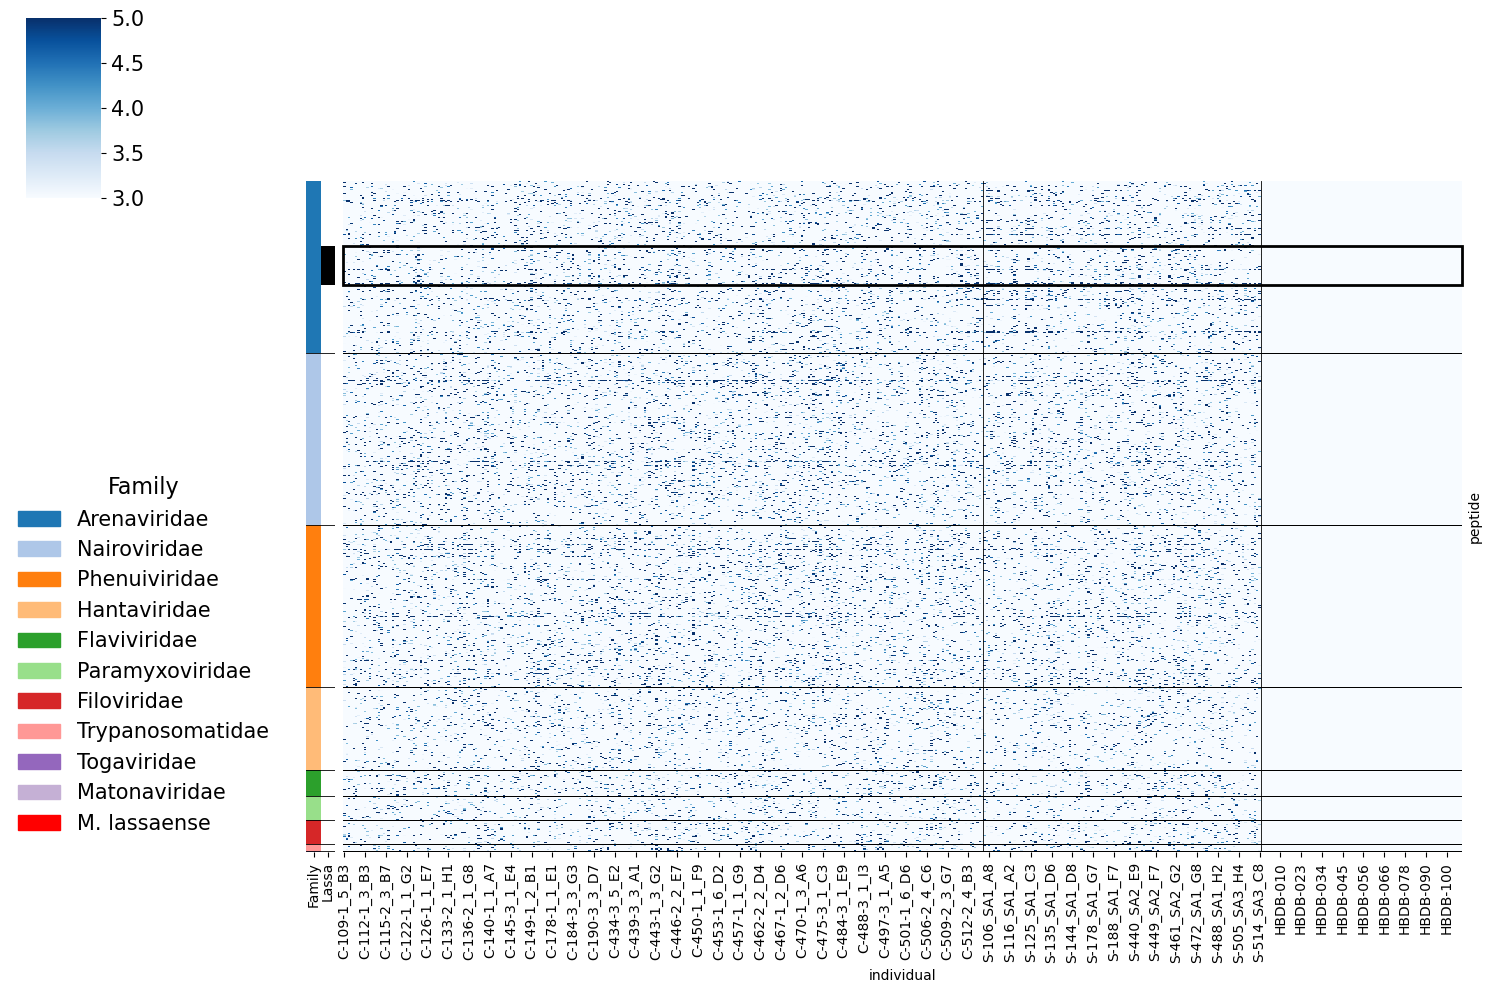

In [5]:
# flag Lassa peptides
is_lassa = pep_hits_meta['species'].eq('Mammarenavirus lassaense')
print(is_lassa.sum(), 'Lassa peptides')   # check it matched

# two color strips: family + Lassa highlight
row_colors = pd.DataFrame({
    'Family': pep_hits_meta['family'].map(genus_lut),
    'Lassa':  is_lassa.map({True: 'black', False: 'white'}),
})

g = sns.clustermap(
    plot_df,
    row_cluster=False,
    col_cluster=False,
    rasterized=True,
    row_colors=row_colors,
    colors_ratio=0.01,
    cmap='Blues',
    yticklabels=False,
    figsize=(15, 10),
    vmin=3, vmax=5,
)

# group dividers (samples)
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

# family dividers (peptides)
counts = pep_hits_meta['family'].value_counts().reindex(genera)
for y in np.cumsum(counts.values)[:-1]:
    g.ax_heatmap.axhline(y, color="black", lw=0.6, snap=True, antialiased=False)
    g.ax_row_colors.axhline(y, color="black", lw=0.6)

# outline the Lassa block on the heatmap
rows = np.flatnonzero(is_lassa.values)
start, end = rows.min(), rows.max() + 1
g.ax_heatmap.add_patch(mpatches.Rectangle(
    (0, start), plot_df.shape[1], end - start,
    fill=False, edgecolor='black', lw=2, clip_on=False,
))

# legend
handles = [mpatches.Patch(color=genus_lut[gn], label=gn) for gn in genera]
handles.append(mpatches.Patch(color='red', label='M. lassaense'))
g.ax_heatmap.legend(handles=handles, title='Family', loc='lower right', frameon=False,
                    bbox_to_anchor=(-0.05, 0), fontsize=15, title_fontsize=16)

g.ax_cbar.tick_params(labelsize=15)

plt.savefig('./svg_figures/peptide_hits_birdseye_view_by_famil_lassa_peps.svg', bbox_inches='tight')
plt.show()

### how many individuals are reactive to at least one lasv peptide?

In [6]:
df_lasv = df.loc[df['species'] == 'Mammarenavirus lassaense']

In [7]:
df_lasv.groupby(['individual', 'category'])['reactive'].any().reset_index().groupby('category')['reactive'].mean().round(2)

category
Household contact    0.99
Lassa survivor       1.00
US healthy           0.00
Name: reactive, dtype: float64

## top genera based on number of peptides 

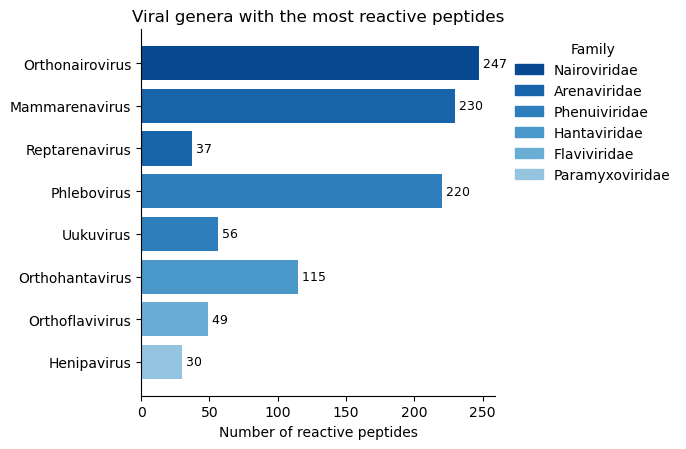

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

hits = pep_hits_meta

hits = hits.reset_index()

def plot_top_genera_grouped(hits, top_k=5, fname=None):

    # Count unique reactive peptides per genus
    g = (
        hits.groupby(["family", "genus"])["peptide"]
            .nunique()
            .reset_index(name="n")
            .sort_values("n", ascending=False)
    )

    # Select top genera OVERALL first
    top = g.head(top_k).copy()

    # Order families according to the strongest genus in each family
    family_order = (
        top.groupby("family")["n"]
           .max()
           .sort_values(ascending=False)
           .index
           .tolist()
    )

    top["family"] = pd.Categorical(
        top["family"],
        categories=family_order,
        ordered=True
    )

    # Group by family; within family, largest first
    top = top.sort_values(
        ["family", "n"],
        ascending=[False, True]
    )

    # Give each family its own color
    families = family_order
    cmap = plt.get_cmap("Blues")

    family_colors = {
        fam: cmap(x)
        for fam, x in zip(
            families,
            np.linspace(0.9, 0.4, len(families))
        )
    }

    y = np.arange(len(top))

    fig, ax = plt.subplots(
        figsize=(7, 0.45 * len(top) + 1)
    )

    ax.barh(
        y,
        top["n"],
        color=[family_colors[f] for f in top["family"]]
    )

    # Just genus on y-axis because family is encoded by grouping/color
    ax.set_yticks(y)
    ax.set_yticklabels(top["genus"])

    # Counts
    for yi, n in zip(y, top["n"]):
        ax.text(
            n,
            yi,
            f" {n}",
            va="center",
            fontsize=9
        )

    ax.set_xlabel("Number of reactive peptides")
    ax.set_title("Viral genera with the most reactive peptides")

    ax.spines[["top", "right"]].set_visible(False)

    # Legend for families
    handles = [
        plt.Rectangle(
            (0, 0), 1, 1,
            color=family_colors[fam],
            label=fam
        )
        for fam in families
    ]

    ax.legend(
        handles=handles,
        title="Family",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    if fname:
        plt.savefig(fname, bbox_inches="tight")

    plt.show()

    return top


top_genera = plot_top_genera_grouped(
    hits,
    top_k=8,
    fname="svg_figures/bar_top_genera_grouped.svg"
)

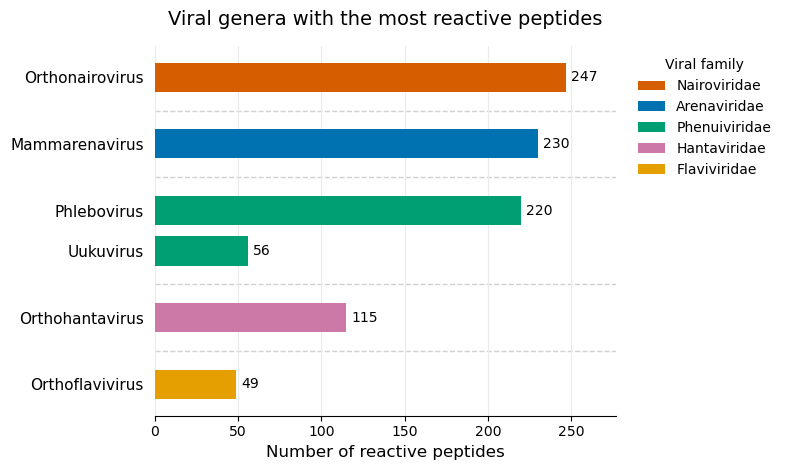

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

hits = pep_hits_meta.reset_index()

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
           "#E69F00", "#56B4E9", "#7A7A7A"]

_fam_rank = (hits.groupby("family")["peptide"].nunique()
             .sort_values(ascending=False).index.tolist())

FAMILY_COLORS = {fam: PALETTE[i % len(PALETTE)] for i, fam in enumerate(_fam_rank)}

GENUS_FAMILY = hits.drop_duplicates("genus").set_index("genus")["family"]
GENUS_COLORS = {gen: FAMILY_COLORS[f] for gen, f in GENUS_FAMILY.items()}
def plot_top_genera_grouped(hits, top_k=8, fname=None):

    # ---------------------------------------------------------
    # 1. Count unique reactive peptides per genus
    # ---------------------------------------------------------
    g = (
        hits.groupby(["family", "genus"])["peptide"]
            .nunique()
            .reset_index(name="n")
            .sort_values("n", ascending=False)
    )

    # Select top genera OVERALL
    top = g.head(top_k).copy()

    # ---------------------------------------------------------
    # 2. Order families by strongest genus
    # ---------------------------------------------------------
    family_order = (
        top.groupby("family")["n"]
           .max()
           .sort_values(ascending=False)
           .index
           .tolist()
    )


    # ---------------------------------------------------------
    # 4. Build plotting order and add gaps between families
    # ---------------------------------------------------------
    rows = []
    y_positions = []
    family_centers = {}
    separators = []

    y = 0
    gap = 0.65

    for i, fam in enumerate(family_order):

        fam_df = (
            top[top["family"] == fam]
            .sort_values("n", ascending=False)
        )

        fam_positions = []

        for _, row in fam_df.iterrows():
            rows.append(row)
            y_positions.append(y)
            fam_positions.append(y)
            y += 1

        # Position for family label
        family_centers[fam] = np.mean(fam_positions)

        # Separator between families
        if i < len(family_order) - 1:
            separators.append(y - 0.5 + gap / 2)
            y += gap

    plot_df = pd.DataFrame(rows)

    # ---------------------------------------------------------
    # 5. Plot
    # ---------------------------------------------------------

    family_colors = FAMILY_COLORS
    
    fig, ax = plt.subplots(
        figsize=(8, 0.55 * len(top) + 1.5)
    )

    ax.barh(
        y_positions,
        plot_df["n"],
        height=0.72,
        color=[family_colors[f] for f in plot_df["family"]],
        edgecolor="none"
    )

    # Genus labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_df["genus"],
        fontsize=11
    )

    # Largest family at top
    ax.invert_yaxis()

    # ---------------------------------------------------------
    # 6. Add counts
    # ---------------------------------------------------------
    xmax = plot_df["n"].max()

    for yi, n in zip(y_positions, plot_df["n"]):
        ax.text(
            n + xmax * 0.012,
            yi,
            f"{n}",
            va="center",
            ha="left",
            fontsize=10
        )

    # Give count labels room
    ax.set_xlim(0, xmax * 1.12)

    # ---------------------------------------------------------
    # 7. FAMILY SEPARATORS
    # ---------------------------------------------------------
    for sep in separators:
        ax.axhline(
            sep,
            color="0.82",
            linewidth=1,
            linestyle="--",
            zorder=0
        )

    # ---------------------------------------------------------
    # 8. Labels / formatting
    # ---------------------------------------------------------
    ax.set_xlabel(
        "Number of reactive peptides",
        fontsize=12
    )

    ax.set_title(
        "Viral genera with the most reactive peptides",
        fontsize=14,
        pad=15
    )

    ax.spines[["top", "right", "left"]].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
        pad=8
    )

    # Very subtle x grid
    ax.grid(
        axis="x",
        color="0.92",
        linewidth=0.8
    )
    ax.set_axisbelow(True)

    # ---------------------------------------------------------
    # 9. Family legend
    # ---------------------------------------------------------
    handles = [
        Patch(
            facecolor=family_colors[fam],
            label=fam
        )
        for fam in family_order
    ]

    ax.legend(
        handles=handles,
        title="Viral family",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=10,
        title_fontsize=10
    )

    plt.tight_layout()

    if fname:
        plt.savefig(
            fname,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

    return plot_df


top_genera = plot_top_genera_grouped(
    hits,
    top_k=6,
    fname="svg_figures/bar_top_genera_grouped.svg"
)

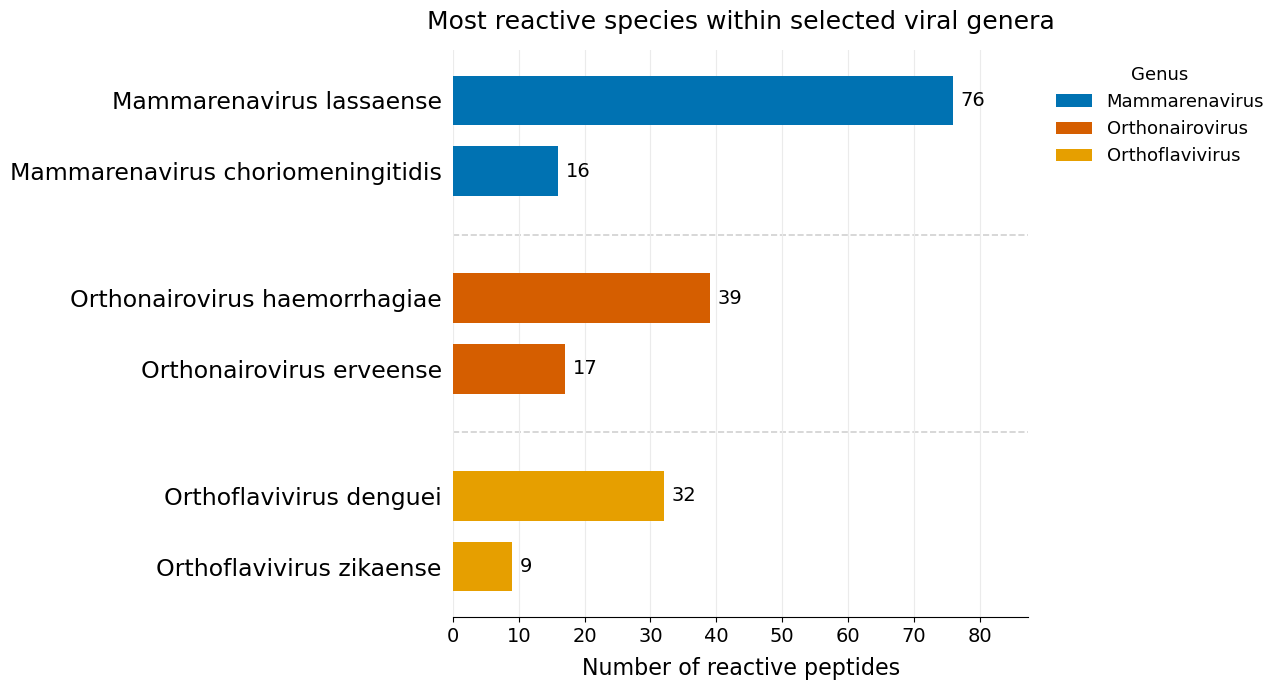

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

hits = pep_hits_meta.reset_index()

def plot_top_species_by_genus(
    hits,
    genera=("Mammarenavirus", "Orthonairovirus", "Orthoflavivirus"),
    top_k=2,
    fname=None
):

    # ---------------------------------------------------------
    # 1. Count unique reactive peptides per species
    # ---------------------------------------------------------
    g = (
        hits[hits["genus"].isin(genera)]
        .groupby(["family", "genus", "species"])["peptide"]
        .nunique()
        .reset_index(name="n")
    )

    # ---------------------------------------------------------
    # 2. Select top 2 species WITHIN each genus
    # ---------------------------------------------------------
    top = (
        g.sort_values("n", ascending=False)
         .groupby("genus", group_keys=False)
         .head(top_k)
         .copy()
    )

    # Keep genus order exactly as specified above
    genus_order = list(genera)

    # ---------------------------------------------------------
    # 3. SAME COLORS as previous figure
    # ---------------------------------------------------------
    genus_colors = GENUS_COLORS

    # ---------------------------------------------------------
    # 4. Build plotting positions with gaps between genera
    # ---------------------------------------------------------
    rows = []
    y_positions = []
    separators = []

    y = 0
    gap = 0.8

    for i, genus in enumerate(genus_order):

        genus_df = (
            top[top["genus"] == genus]
            .sort_values("n", ascending=False)
        )

        for _, row in genus_df.iterrows():
            rows.append(row)
            y_positions.append(y)
            y += 1

        # Add gap between genera
        if i < len(genus_order) - 1:
            separators.append(y - 0.5 + gap / 2)
            y += gap

    plot_df = pd.DataFrame(rows)

    # ---------------------------------------------------------
    # 5. Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(13, 7)
    )

    ax.barh(
        y_positions,
        plot_df["n"],
        height=0.7,
        color=[
            genus_colors[g]
            for g in plot_df["genus"]
        ],
        edgecolor="none"
    )

    # Species labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_df["species"],
        fontsize=17
    )

    # Largest species at top
    ax.invert_yaxis()

    # ---------------------------------------------------------
    # 6. Add counts
    # ---------------------------------------------------------
    xmax = plot_df["n"].max()

    for yi, n in zip(y_positions, plot_df["n"]):
        ax.text(
            n + xmax * 0.015,
            yi,
            f"{n}",
            va="center",
            ha="left",
            fontsize=14
        )

    ax.set_xlim(0, xmax * 1.15)

    # ---------------------------------------------------------
    # 7. Separators between genera
    # ---------------------------------------------------------
    for sep in separators:
        ax.axhline(
            sep,
            color="0.82",
            linewidth=1.2,
            linestyle="--",
            zorder=0
        )

    # ---------------------------------------------------------
    # 8. Formatting
    # ---------------------------------------------------------
    ax.set_xlabel(
        "Number of reactive peptides",
        fontsize=16,
        labelpad=8
    )

    ax.set_title(
        "Most reactive species within selected viral genera",
        fontsize=18,
        pad=15
    )

    ax.tick_params(
        axis="x",
        labelsize=14
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=8
    )

    ax.spines[["top", "right", "left"]].set_visible(False)

    # Subtle x-axis grid
    ax.grid(
        axis="x",
        color="0.92",
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    # ---------------------------------------------------------
    # 9. Legend = genus
    # ---------------------------------------------------------
    handles = [
        Patch(
            facecolor=genus_colors[genus],
            label=genus
        )
        for genus in genus_order
    ]

    ax.legend(
        handles=handles,
        title="Genus",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=13,
        title_fontsize=13
    )

    plt.tight_layout()

    if fname:
        plt.savefig(
            fname,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

    return plot_df


top_species = plot_top_species_by_genus(
    hits,
    genera=[
        "Mammarenavirus",
        "Orthonairovirus",
        "Orthoflavivirus"
    ],
    top_k=2,
    fname="svg_figures/bar_top_species_selected_genera.svg"
)

In [48]:
lassa = df.loc[df['species'] == 'Mammarenavirus lassaense']

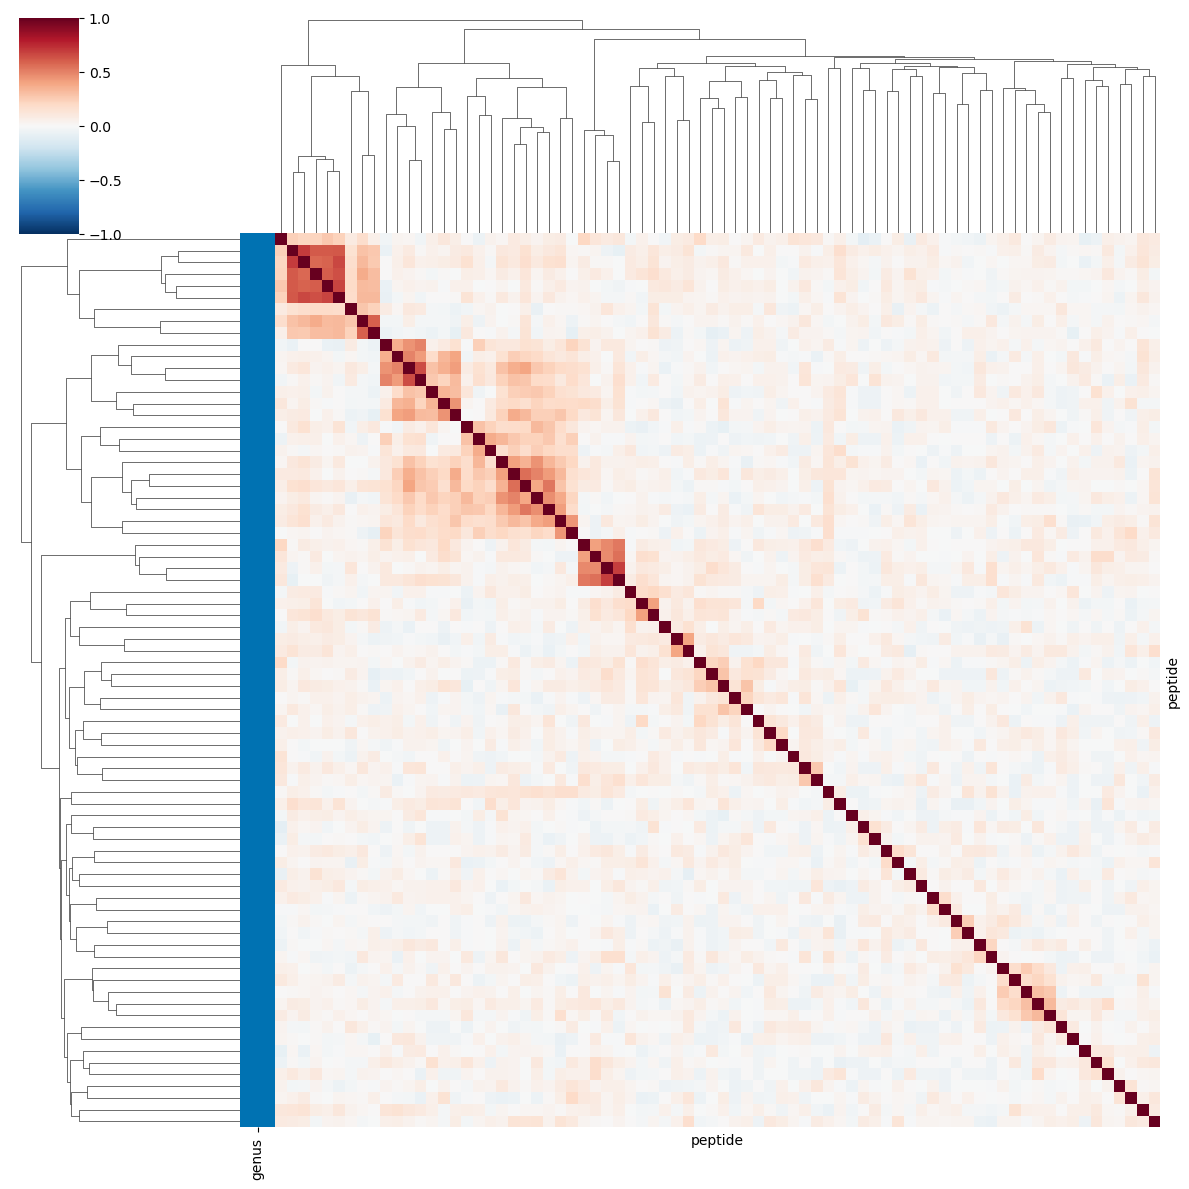

In [54]:
M = lassa.pivot_table(index='individual', columns='peptide', values='reactive', 
                      aggfunc='max', fill_value=0)

M = M.loc[:, M.sum() >= 10] #drop rare peptides
corr = M.corr()

sns.clustermap(corr, cmap='RdBu_r', vmin=-1, vmax=1,
               figsize=(12, 12), xticklabels=False, yticklabels=False,
               row_colors=pep_hits_meta.loc[corr.index, 'genus'].map(GENUS_COLORS),
               rasterized=True)

In [50]:
M 

peptide,AHC95546.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Mar-2012|L|Bamba-R114|tile_13,AHC95546.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Mar-2012|L|Bamba-R114|tile_56,AHC95546.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Mar-2012|L|Bamba-R114|tile_69,AIT17175.1|polymerase|Mammarenavirus_lassaense|?|Homo_sapiens|Liberia|2010|L|G1200-LIB-2010|tile_9,AIT17179.1|polymerase|Mammarenavirus_lassaense|?|Homo_sapiens|Sierra_Leone|2011|L|G1442-SLE-2011|tile_21,AIT17273.1|polymerase|Mammarenavirus_lassaense|?|Homo_sapiens|Sierra_Leone|2012|L|G2363-SLE-2012|tile_21,AIT17661.1|polymerase|Mammarenavirus_lassaense|?|Homo_sapiens|Nigeria|2011|L|LASV250-NIG-2011|tile_41,AIT17661.1|polymerase|Mammarenavirus_lassaense|?|Homo_sapiens|Nigeria|2011|L|LASV250-NIG-2011|tile_82,ANH09740.1|precursor|Mammarenavirus_lassaense|?|Hylomyscus_pamfi|Nigeria|15-Mar-2012|?|KAK-428|tile_7,ANH09741.1|nucleoprotein|Mammarenavirus_lassaense|?|Hylomyscus_pamfi|Nigeria|15-Mar-2012|?|KAK-428|tile_6,...,UKY81276.1|protein|Mammarenavirus_lassaense|813878|Homo_sapiens|Nigeria|2007|L|?|tile_9,USR47359.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Sierra_Leone:_Bafodia|07-Sep-2019|L|M.natalensis-wt/SLE/2019/Bafodia-00106|tile_21,USR47363.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Sierra_Leone:_Makump|02-Aug-2019|L|M.natalensis-wt/SLE/2019/Makump-00052|tile_9,USR47367.1|polymerase|Mammarenavirus_lassaense|?|Lophuromys_sikapusi|Sierra_Leone:_Barlie|13-Jul-2019|L|L.sikapusi-wt/SLE/2019/Barlie-00019|tile_39,UTE79751.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Sierra_Leone:_Barlie|05-Feb-2020|L|M.natalensis/SLE/2020/Barlie-00512|tile_39,WKK95338.1|nucleoprotein|Mammarenavirus_lassaense|G-27645-1-2|Homo_sapiens|Sierra_Leone:_KGH|17-May-2022|?|?|tile_16,WNI01985.1|nucleoprotein|Mammarenavirus_lassaense|c0141-2|Homo_sapiens|Nigeria|10-Feb-2018|S|?|tile_16,WPS90786.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Guinea:_Silimi|06-Dec-2013|?|Sil-03|tile_10,WPS90786.1|polymerase|Mammarenavirus_lassaense|?|Mastomys_natalensis|Guinea:_Silimi|06-Dec-2013|?|Sil-03|tile_95,XQN12076.1|polymerase|Mammarenavirus_lassaense|?|guinea_pig|USA|12-Dec-1978|L|Josiah|tile_12
individual,,,,,,,,,,,,,,,,,,,,,
C-109-1_5_B3,False,False,False,True,False,False,False,False,False,False,...,False,False,False,True,True,False,False,False,False,False
C-109-2_5_B5,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
C-109-3_4_E7,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,True,True,False,True,False
C-110-1_2_A5,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
C-110-2_3_F8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S-510_SA3_D5,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,True,True,False,False,False
S-511_SA5_A6,False,False,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,False,False,False
S-512_SA3_G9,True,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,True,True,False,False,False


### what is the overall seroprevalence we can get from the top 3 peptides for these species?

In [46]:
best_lasv_peptide['sensitivity'].mean().round(2)

np.float64(0.1)

## fraction of peptide hits

In [ ]:
hits = (plot_df > 3).astype(int)

lib_size = peps_metadata.groupby('species').size()

by_species = hits.groupby(pep_hits_meta['species']).sum() #hits per species per sample

frac = by_species.div(lib_size, axis=0)

In [ ]:
topk = (plot_df.groupby(pep_hits_meta['species'])
                .apply(lambda d: d.apply(lambda c: c.nlargest(3).mean())))

KeyboardInterrupt: 

In [ ]:
# species -> family (one row per species now)
sp_meta = (pep_hits_meta[['species', 'family']]
           .drop_duplicates()
           .set_index('species'))

# sort: families by size, then species
sp_meta['family_n'] = sp_meta.groupby('family')['species'].transform('size') #any column works to get the peptide size of the family
sp_meta = sp_meta.sort_values(['family_n', 'family'], ascending=[False, True]).drop(columns='family_n')

topk = topk.reindex(sp_meta.index)
families = sp_meta['family'].unique()

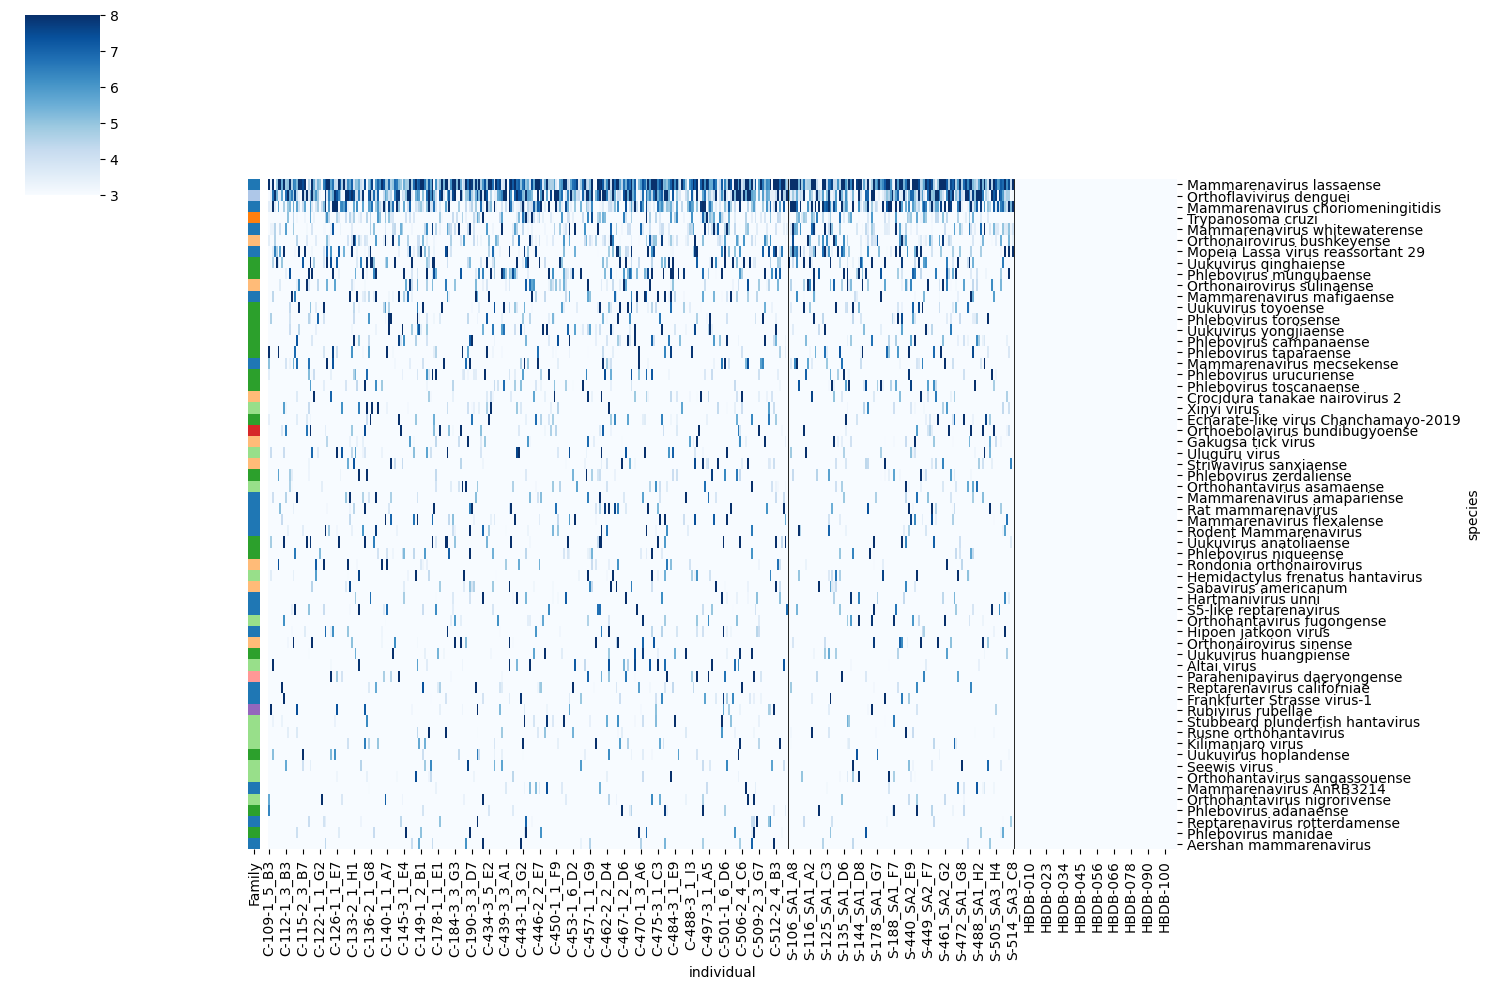

In [ ]:
cutoff = 3

# species -> family
sp_meta = (pep_hits_meta[['species', 'family']]
           .drop_duplicates()
           .set_index('species'))

# filter: pick ONE -> only keep species where people have at least 3 peptides of that species passing z > 3
keep = (topk > cutoff).sum(axis=1) >= 3
topk = topk.loc[keep]

# seroprevalence sort, most to least
seroprev = (topk > cutoff).mean(axis=1)
topk = topk.loc[seroprev.sort_values(ascending=False).index]

# realign metadata to the filtered + sorted rows
sp_meta = sp_meta.loc[topk.index]
families = sp_meta['family'].unique()

palette = sns.color_palette('tab20', n_colors=len(families))
fam_lut = dict(zip(families, palette))
row_colors = sp_meta['family'].map(fam_lut).rename('Family')

g = sns.clustermap(
    topk, row_cluster=False, col_cluster=False,
    row_colors=row_colors, colors_ratio=0.01,
    cmap='Blues', yticklabels=True, figsize=(15, 10),
    rasterized=True, vmin=3, vmax=8,
)

for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

In [ ]:
sp = (pep_hits_meta[['species', 'genus', 'family']]
      .drop_duplicates().set_index('species')
      .loc[topk.index].copy())

sp['seroprev'] = (topk > cutoff).mean(axis=1)

best = sp.groupby('genus')['seroprev'].idxmax()      # one species per genus
topg = topk.loc[best.values]
sp_g = sp.loc[best.values]

# order by seroprevalence
order = sp_g['seroprev'].sort_values(ascending=False).index
topg, sp_g = topg.loc[order], sp_g.loc[order]

# label rows by genus, keeping the species in parentheses
topg.index = sp_g['genus'] + ' (' + sp_g.index + ')'

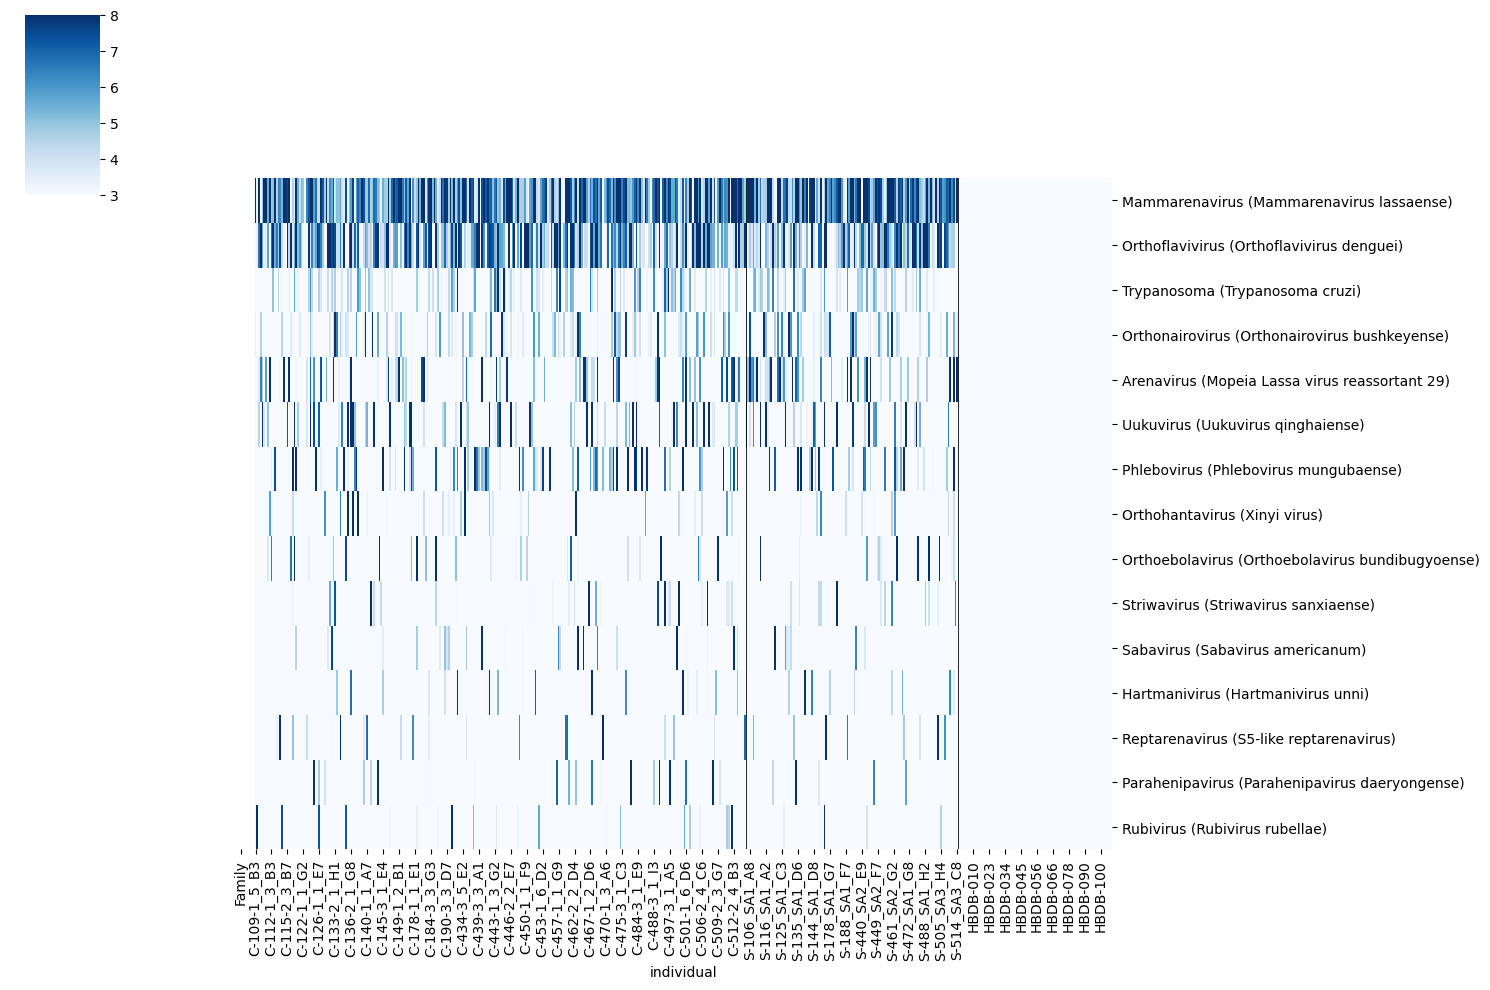

In [ ]:
g = sns.clustermap(
    topg, row_cluster=False, col_cluster=False,
    row_colors=row_colors, colors_ratio=0.01,
    cmap='Blues', yticklabels=True, figsize=(15, 10),
    rasterized=True, vmin=3, vmax=8,
)

for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

In [ ]:
# per-species z against the healthy distribution
hbdb_cols   = topk.columns[topk.columns.str.startswith('HBDB')]
cohort_cols = topk.columns[~topk.columns.str.startswith('HBDB')]

print(len(hbdb_cols), len(cohort_cols), topk.shape[1])   # should sum to the total
mu  = topk[hbdb_cols].mean(axis=1)
sd  = topk[hbdb_cols].std(axis=1)
topz = topk.sub(mu, axis=0).div(sd, axis=0)

87 397 484


In [ ]:
topz

individual,C-109-1_5_B3,C-109-2_5_B5,C-109-3_4_E7,C-110-1_2_A5,C-110-2_3_F8,C-110-3_2_E6,C-111-1_2_H8,C-111-2_3_I5,C-111-3_3_I6,C-112-1_3_B3,...,HBDB-097,HBDB-098,HBDB-099,HBDB-100,HBDB-102,HBDB-106,HBDB-107,HBDB-109,HBDB-111,HBDB-115
species,,,,,,,,,,,,,,,,,,,,,
Mammarenavirus lassaense,19.028540,3.250026,20.700434,0.905931,8.322102,34.514529,18.406277,10.110560,38.651629,8.243505,...,-0.159421,0.305404,-0.122203,1.000131,-0.447764,1.320824,-0.075326,0.718559,0.579443,0.877332
Orthoflavivirus denguei,2.699567,3.623715,11.525361,16.495074,8.628953,3.733786,3.695978,9.022386,1.342710,11.638002,...,0.902017,-0.404242,1.326804,-0.449152,0.953941,0.697446,0.318136,-1.095574,-0.701602,-1.657415
Mammarenavirus choriomeningitidis,4.122980,3.668064,15.700680,4.220261,-0.532765,8.627720,-0.921136,1.455671,6.444947,3.074335,...,1.035432,1.651568,1.443950,-1.586791,-0.644044,0.850815,0.173251,-1.894649,0.300749,1.788283
Trypanosoma cruzi,1.530832,0.063563,2.479627,-1.346230,-2.898626,2.370812,-1.310258,1.517201,-0.494752,0.504284,...,0.784252,1.424756,1.070716,0.911539,0.817880,-0.797740,-0.555435,-0.988616,0.673401,0.630045
Mammarenavirus whitewaterense,-0.570835,3.716108,3.714229,5.824324,-3.470265,1.048798,5.075238,-1.984614,3.110760,8.213738,...,0.685573,2.169409,-0.742571,-1.521405,1.567512,0.169361,0.787076,-1.596379,-1.535226,-1.447261
Orthonairovirus bushkeyense,4.171100,0.036417,-1.325126,6.040879,-0.057740,3.200953,-1.579668,-1.667361,1.516580,1.996663,...,-1.301596,0.705938,1.083961,0.790349,1.125713,0.851303,-1.811725,-0.605631,-0.646440,1.360167
Mopeia Lassa virus reassortant 29,1.498457,0.409289,3.562744,6.314891,4.569909,0.216480,5.666160,0.276964,11.095208,-0.185734,...,0.938683,-0.138597,-1.670131,-0.660935,2.468040,0.062904,-0.717962,1.172831,-0.397428,-0.974048
Uukuvirus qinghaiense,-0.716863,-0.716863,4.402610,0.332989,8.593788,3.667290,2.036586,4.834356,1.624794,-0.716863,...,-0.723165,-0.723165,-0.723165,1.722020,-0.723165,-0.723165,0.073910,2.020049,0.013501,-0.723165
Phlebovirus mungubaense,0.270547,1.382671,0.766570,0.015242,-1.167583,2.134070,0.015418,1.217461,-0.161506,3.403904,...,-0.848302,1.235636,-1.184088,-1.184088,-0.745690,2.423059,0.373626,-1.184088,0.992258,-1.184088


## now looking at which viral species dominate each family